# Model Parameterization Demos

This notebook contrasts how common sampling and decoding parameters change model output on the **ITBA LiteLLM proxy**. It runs the same fixed prompts against two proxy model names — `gpt-5.2-mini` and `claude-haiku-4-5` — and walks through:

| Parameter | Demo |
| --- | --- |
| `temperature` | Demo 1 — Temperature (quantified classification variance) |
| `top_p` | Demo 2 — top_p (nucleus sampling) |
| `max_tokens` | Demo 3 — max_tokens |
| `presence_penalty` | Demo 4 — presence_penalty |
| `frequency_penalty` | Demo 5 — frequency_penalty |
| `seed` | Demo 6 — seed / reproducibility |

Demo 1 reports metrics across many trials; demos 2–6 show side-by-side sample replies (or explicit skip notes when a parameter is unsupported). All narrative and identifiers are in English. Credentials come from the repo-root `.env` (`LLM_SERVICE_URL`, `LLM_API_KEY`); the notebook never uses vendor API keys directly.

## Setup

In [ ]:
import os
from pathlib import Path

from dotenv import load_dotenv

ENV_PATH = Path(".env")

if not ENV_PATH.is_file():
    raise RuntimeError(
        f"Repo-root .env not found at {ENV_PATH.resolve()}. "
        "Create it with LLM_SERVICE_URL and LLM_API_KEY before running this notebook."
    )

load_dotenv(dotenv_path=ENV_PATH)

LLM_SERVICE_URL = os.environ.get("LLM_SERVICE_URL", "")
LLM_API_KEY = os.environ.get("LLM_API_KEY", "")
LLM_MODEL = os.environ.get("LLM_MODEL", "")  # diagnostic only; never used for MODELS

missing = [
    name
    for name, value in (
        ("LLM_SERVICE_URL", LLM_SERVICE_URL),
        ("LLM_API_KEY", LLM_API_KEY),
    )
    if not value
]
if missing:
    raise RuntimeError(
        f"Missing required environment variable(s): {', '.join(missing)}. "
        f"Set them in {ENV_PATH.resolve()} before running this notebook."
    )

print(f"LLM_SERVICE_URL present: {bool(LLM_SERVICE_URL)}")
print(f"LLM_API_KEY present: {bool(LLM_API_KEY)}")
print(f"LLM_MODEL present: {bool(LLM_MODEL)}")

LLM_SERVICE_URL present: True
LLM_API_KEY present: True
LLM_MODEL present: True


> **Cost / volume warning.** Running every demo at full defaults across both models in `MODELS` issues on the order of **~150–170 completion calls** (Demo 1 alone is 60 × 2 = 120; demos 2–6 add on the order of tens more — e.g. Demo 2: 3×2, Demo 3: 3×2, Demo 4: 2×2, Demo 5: 2×2, Demo 6: up to 5×2). A full `Restart & Run All` can take tens of minutes and consume non-trivial token spend. Run individual demo sections first if you want to control cost or time.

In [ ]:
import time
from dataclasses import dataclass

from langchain_core.messages import AIMessage, HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI

RETRY_ATTEMPTS = 3
RETRY_BACKOFF_SECONDS = (1, 2, 4)


class DemoLLMError(Exception):
    """Raised when a chat() call fails after exhausting retries or hits a non-transient error."""


def _iter_exception_chain(exc: BaseException):
    seen: set[int] = set()
    current: BaseException | None = exc
    while current is not None and id(current) not in seen:
        seen.add(id(current))
        yield current
        current = current.__cause__ or current.__context__


def _status_code(exc: BaseException) -> int | None:
    for item in _iter_exception_chain(exc):
        code = getattr(item, "status_code", None)
        if code is not None:
            return int(code)
        response = getattr(item, "response", None)
        if response is not None:
            code = getattr(response, "status_code", None)
            if code is not None:
                return int(code)
    return None


def _is_transient_error(exc: Exception) -> bool:
    status = _status_code(exc)
    if status is not None:
        return status == 429 or status >= 500
    message = str(exc).lower()
    return any(
        token in message
        for token in ("429", "500", "502", "503", "504", "timeout", "connection")
    )


def _is_client_validation_error(exc: Exception) -> bool:
    """True for local/client validation failures (no HTTP), e.g. unexpected kwargs."""
    if _status_code(exc) is not None:
        return False
    name = type(exc).__name__.lower()
    message = str(exc).lower()
    if "validation" in name:
        return True
    if isinstance(exc, (TypeError, ValueError)):
        return True
    return any(
        token in message
        for token in ("unexpected keyword", "validation error", "invalid argument")
    )


def _is_unsupported_parameter(exc: Exception, param_name: str) -> bool:
    """BR-008: unsupported/rejected parameter (not transient; not auth)."""
    if _is_transient_error(exc):
        return False

    status = _status_code(exc)
    if status in (401, 403):
        return False

    http_reject = status in (400, 422)
    client_validation = _is_client_validation_error(exc)
    if not http_reject and not client_validation:
        message_for_status = str(exc).lower()
        if any(
            token in message_for_status
            for token in ("401", "403", "unauthorized", "forbidden")
        ):
            return False
        http_reject = any(
            token in message_for_status for token in ("400", "422", "bad request")
        )
        if not http_reject:
            return False

    message = str(exc).lower()
    needles = (
        "unsupported",
        "unknown parameter",
        "unexpected keyword",
        "invalid parameter",
        "does not support",
        param_name.lower(),
    )
    return any(needle in message for needle in needles)


def _to_langchain_messages(messages: list[dict]) -> list:
    role_to_class = {
        "system": SystemMessage,
        "user": HumanMessage,
        "assistant": AIMessage,
    }
    converted = []
    for message in messages:
        role = message["role"]
        if role not in role_to_class:
            raise ValueError(f"Unsupported message role: {role!r}")
        converted.append(role_to_class[role](content=message["content"]))
    return converted


def _proxy_base_url(service_url: str | None = None) -> str:
    url = LLM_SERVICE_URL if service_url is None else service_url
    return f"{url.rstrip('/')}/v1"


def chat(
    model: str,
    messages: list[dict],
    *,
    temperature: float = 0,
    top_p: float | None = None,
    max_tokens: int | None = None,
    presence_penalty: float | None = None,
    frequency_penalty: float | None = None,
    seed: int | None = None,
) -> str:
    """Call `model` via the ITBA LiteLLM proxy through LangChain's ChatOpenAI and return the reply text."""
    kwargs: dict = {
        "base_url": _proxy_base_url(),
        "api_key": LLM_API_KEY,
        "model": model,
        "temperature": temperature,
    }
    if top_p is not None:
        kwargs["top_p"] = top_p
    if max_tokens is not None:
        kwargs["max_tokens"] = max_tokens
    if presence_penalty is not None:
        kwargs["presence_penalty"] = presence_penalty
    if frequency_penalty is not None:
        kwargs["frequency_penalty"] = frequency_penalty
    if seed is not None:
        kwargs["seed"] = seed

    llm = ChatOpenAI(**kwargs)
    lc_messages = _to_langchain_messages(messages)

    last_error: Exception | None = None
    for attempt in range(RETRY_ATTEMPTS):
        try:
            reply: AIMessage = llm.invoke(lc_messages)
            return str(reply.content)
        except Exception as exc:  # noqa: BLE001 - classify below
            last_error = exc
            if not _is_transient_error(exc) or attempt == RETRY_ATTEMPTS - 1:
                raise DemoLLMError(f"chat() failed for model={model!r}: {exc}") from exc
            time.sleep(RETRY_BACKOFF_SECONDS[attempt])

    raise DemoLLMError(f"chat() failed for model={model!r}: {last_error}")


@dataclass
class ChatResult:
    ok: bool
    text: str | None = None
    skipped: bool = False
    unsupported: bool = False
    error: str | None = None
    model: str | None = None
    param_name: str | None = None


def safe_chat(
    model: str,
    messages: list[dict],
    *,
    param_name: str | None = None,
    temperature: float = 0,
    top_p: float | None = None,
    max_tokens: int | None = None,
    presence_penalty: float | None = None,
    frequency_penalty: float | None = None,
    seed: int | None = None,
) -> ChatResult:
    """Call chat(); on DemoLLMError print a skip note and return a result object (FR-003 / BR-008)."""
    try:
        text = chat(
            model,
            messages,
            temperature=temperature,
            top_p=top_p,
            max_tokens=max_tokens,
            presence_penalty=presence_penalty,
            frequency_penalty=frequency_penalty,
            seed=seed,
        )
        return ChatResult(ok=True, text=text, model=model, param_name=param_name)
    except DemoLLMError as exc:
        unsupported = param_name is not None and _is_unsupported_parameter(
            exc, param_name
        )
        if unsupported:
            note = (
                f"SKIP unsupported/rejected parameter: model={model!r} "
                f"parameter={param_name!r} — {exc}"
            )
        else:
            note = f"SKIP error: model={model!r} parameter={param_name!r} — {exc}"
        print(note)
        return ChatResult(
            ok=False,
            skipped=True,
            unsupported=unsupported,
            error=str(exc),
            model=model,
            param_name=param_name,
        )


In [15]:
# Fixed two-model list for all demos (BR-006). Do not substitute LLM_MODEL.
MODELS: list[str] = ["gpt-4.1-mini", "gpt-4.1", "gpt-4.1-nano"]

print(f"MODELS: {MODELS}")
print(f"LLM_MODEL (diagnostic only): {'set' if LLM_MODEL else 'unset'}")

MODELS: ['gpt-4.1-mini', 'gpt-4.1', 'gpt-4.1-nano']
LLM_MODEL (diagnostic only): set


## Infrastructure checks

Unit-style exercises for helper classification, `base_url` slash handling, default temperature, and forced-failure handling. These checks do not call the live proxy and are not part of the classroom demos.

In [16]:
class _FakeHTTPError(Exception):
    def __init__(self, message: str, status_code: int | None = None):
        super().__init__(message)
        self.status_code = status_code


# VC-023: transient / unsupported / auth classification
assert _is_transient_error(_FakeHTTPError("rate limited", 429))
assert _is_transient_error(_FakeHTTPError("server blew up", 503))
assert _is_transient_error(TimeoutError("timeout waiting for proxy"))
assert _is_transient_error(ConnectionError("connection reset"))
assert not _is_transient_error(
    _FakeHTTPError("bad request unsupported presence_penalty", 400)
)
assert not _is_transient_error(_FakeHTTPError("unauthorized", 401))

assert _is_unsupported_parameter(
    _FakeHTTPError("Unsupported parameter: presence_penalty", 400),
    "presence_penalty",
)
assert _is_unsupported_parameter(
    _FakeHTTPError("unknown parameter frequency_penalty", 422),
    "frequency_penalty",
)
assert _is_unsupported_parameter(
    TypeError("ChatOpenAI.__init__() got an unexpected keyword argument 'seed'"),
    "seed",
)
assert not _is_unsupported_parameter(_FakeHTTPError("unauthorized", 401), "seed")
assert not _is_unsupported_parameter(
    _FakeHTTPError("forbidden", 403), "presence_penalty"
)
assert not _is_unsupported_parameter(_FakeHTTPError("rate limited", 429), "top_p")
print("VC-023 classifier unit checks: PASS")


# VC-023: transient retries ≤ 3 then raise; non-transient not retried
class _CountingLLM:
    def __init__(self, exc: Exception):
        self.exc = exc
        self.calls = 0

    def invoke(self, _messages):
        self.calls += 1
        raise self.exc


_original_chat_openai = ChatOpenAI
_original_sleep = time.sleep
time.sleep = lambda _s: None  # type: ignore[assignment]

try:
    transient_llm = _CountingLLM(_FakeHTTPError("503 service unavailable", 503))

    def _factory_transient(**_kwargs):
        return transient_llm

    ChatOpenAI = _factory_transient  # type: ignore[misc, assignment]
    try:
        chat("dummy", [{"role": "user", "content": "ping"}])
        raise AssertionError("expected DemoLLMError for transient exhaustion")
    except DemoLLMError:
        pass
    assert transient_llm.calls == RETRY_ATTEMPTS, transient_llm.calls

    auth_llm = _CountingLLM(_FakeHTTPError("unauthorized", 401))

    def _factory_auth(**_kwargs):
        return auth_llm

    ChatOpenAI = _factory_auth  # type: ignore[misc, assignment]
    try:
        chat("dummy", [{"role": "user", "content": "ping"}])
        raise AssertionError("expected DemoLLMError for auth failure")
    except DemoLLMError:
        pass
    assert auth_llm.calls == 1, auth_llm.calls

    unsupported_llm = _CountingLLM(
        _FakeHTTPError("does not support presence_penalty", 400)
    )

    def _factory_unsupported(**_kwargs):
        return unsupported_llm

    ChatOpenAI = _factory_unsupported  # type: ignore[misc, assignment]
    try:
        chat("dummy", [{"role": "user", "content": "ping"}], presence_penalty=1.5)
        raise AssertionError("expected DemoLLMError for unsupported param")
    except DemoLLMError:
        pass
    assert unsupported_llm.calls == 1, unsupported_llm.calls
    print("VC-023 retry behavior: PASS")
finally:
    ChatOpenAI = _original_chat_openai  # type: ignore[misc]
    time.sleep = _original_sleep  # type: ignore[assignment]

# VC-026: forced failure raises; safe_chat does not treat message as model output
_real_chat = chat


def _boom_chat(*_args, **_kwargs):
    raise DemoLLMError(
        "chat() failed for model='gpt-5.2-mini': forced failure for VC-026"
    )


globals()["chat"] = _boom_chat
try:
    try:
        chat("gpt-5.2-mini", [{"role": "user", "content": "ping"}])
        raise AssertionError("chat should have raised")
    except DemoLLMError:
        pass
    skip = safe_chat(
        "gpt-5.2-mini",
        [{"role": "user", "content": "ping"}],
        param_name="temperature",
    )
    assert skip.ok is False and skip.skipped is True
    assert skip.text is None
    assert "forced failure" in (skip.error or "")
    assert skip.text != skip.error
    print("VC-026 forced failure + skip (not model output): PASS")
finally:
    globals()["chat"] = _real_chat

print("All Iteration-1 infrastructure checks passed.")


VC-023 classifier unit checks: PASS
VC-023 retry behavior: PASS
SKIP error: model='gpt-5.2-mini' parameter='temperature' — chat() failed for model='gpt-5.2-mini': forced failure for VC-026
VC-026 forced failure + skip (not model output): PASS
All Iteration-1 infrastructure checks passed.


# Demo 1 — Temperature

**Goal.** Quantify how much a model's classification label varies across independent trials of the same fixed support ticket, at `temperature=0` versus `temperature=1`.

**Method.** Classify one fixed, deliberately ambiguous support-ticket text into exactly one of four fixed categories. For each model in `MODELS`, run **30** independent trials at `temperature=1` and **30** at `temperature=0` (fresh `messages` each trial). Leave all other sampling kwargs at helper defaults (no `top_p`, penalties, or `seed`). Parse each reply with `extract_label` into a discrete category or `"unparsed"`, then report distinct-label count, Shannon entropy, and majority-share per `(model, temperature)`.

**What to look for.** Compare entropy and distinct-label count at temperature 1 vs 0 for the same model. Higher temperature usually increases output diversity (more labels / higher entropy / lower majority-share). At temperature 0, labels are often more peaked — but not always perfectly deterministic. Exact string-match tests against a single "correct" label are unreliable whenever variance is nonzero.

**How to read the result.** Entropy 0 and majority-share 1.0 mean perfect consistency for that condition. Nonzero entropy means some fraction of naive eval "failures" would be sampling variance, not a wrong model. Prefer `temperature=0` when classroom demos need reproducibility; use higher temperature when you intentionally want more diverse samples.

In [17]:
import math
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

DEMO1_N = 30
DEMO1_TEMPERATURES = (
    1,
    0.5,
    0,
)  # FR-010 / VC-022: both arms; other sampling kwargs left at defaults
DEMO1_CATEGORIES = [
    "Bug Report",
    "Feature Request",
    "Account Access",
    "General Inquiry",
]
assert len(DEMO1_CATEGORIES) >= 4

# Deliberately ambiguous: straddles Bug Report (slow login) and Feature Request (dark mode ask).
DEMO1_TICKET = (
    "Subject: Slow\n\n"
    "The app has been really slow to log into lately, sometimes taking a full minute. "
    "Also, is there a dark mode option?"
)

DEMO1_PROMPT = (
    "Classify the following support ticket into exactly one of these categories: "
    f"{', '.join(DEMO1_CATEGORIES)}.\n\n"
    f"Ticket:\n{DEMO1_TICKET}\n\n"
    "Respond with just the category name, no explanation."
)

# Allow-list for BR-011: strip + lowercase exact match, else first substring match.
_DEMO1_CATEGORY_LOOKUP = {c.strip().lower(): c for c in DEMO1_CATEGORIES}


def extract_label(reply: str) -> str:
    """Map a model reply to one DEMO1_CATEGORIES label, or "unparsed" (BR-011).

    Rule (documented):
    1. Strip whitespace and lowercase the reply.
    2. If the whole string exactly matches an allow-listed category (case-insensitive),
       return that canonical category.
    3. Else return the first allow-listed category whose lowercase form appears as a
       substring in the reply (scan order = DEMO1_CATEGORIES).
    4. If nothing matches (including empty reply), return "unparsed".
    """
    text = (reply or "").strip()
    if not text:
        return "unparsed"
    lowered = text.lower()
    if lowered in _DEMO1_CATEGORY_LOOKUP:
        return _DEMO1_CATEGORY_LOOKUP[lowered]
    for category in DEMO1_CATEGORIES:
        if category.lower() in lowered:
            return category
    return "unparsed"


def shannon_entropy(labels: list[str]) -> float:
    total = len(labels)
    if total == 0:
        return float("nan")
    counts = Counter(labels)
    entropy = -sum(
        (count / total) * math.log2(count / total) for count in counts.values()
    )
    # Avoid signed zero from -1 * 0.0 when a single label has probability 1.
    return 0.0 if abs(entropy) < 1e-12 else entropy


def majority_share(labels: list[str]) -> float:
    total = len(labels)
    if total == 0:
        return float("nan")
    return Counter(labels).most_common(1)[0][1] / total


# VC-007 / BR-011: unparseable reply → "unparsed"
assert extract_label("") == "unparsed"
assert extract_label("   ") == "unparsed"
assert extract_label("not a real category") == "unparsed"
assert extract_label("Bug Report") == "Bug Report"
assert extract_label("I think this is a Feature Request.") == "Feature Request"
print("extract_label checks: PASS (empty → 'unparsed')")
print(
    f"DEMO1_N={DEMO1_N}, temperatures={DEMO1_TEMPERATURES}, categories={DEMO1_CATEGORIES}"
)

extract_label checks: PASS (empty → 'unparsed')
DEMO1_N=30, temperatures=(1, 0.5, 0), categories=['Bug Report', 'Feature Request', 'Account Access', 'General Inquiry']


Demo 1 metrics (distinct-label count, Shannon entropy, majority-share):


,model,temperature,n_trials,distinct_label_count,shannon_entropy,majority_share
0,gpt-4.1-mini,1.0,30,2,0.210842,0.966667
1,gpt-4.1-mini,0.5,30,1,0.000000,1.000000
2,gpt-4.1-mini,0.0,30,1,0.000000,1.000000
3,gpt-4.1,1.0,30,2,0.353359,0.933333
4,gpt-4.1,0.5,30,2,0.566510,0.866667
5,gpt-4.1,0.0,30,2,0.566510,0.866667
6,gpt-4.1-nano,1.0,30,2,0.210842,0.966667
7,gpt-4.1-nano,0.5,30,1,0.000000,1.000000
8,gpt-4.1-nano,0.0,30,1,0.000000,1.000000


gpt-4.1-mini @ temperature=1.0: n=30, distinct=2, entropy=0.211, majority_share=0.967
  → entropy > 0: exact-match evaluation against a single label would be unreliable here.
gpt-4.1-mini @ temperature=0.5: n=30, distinct=1, entropy=0.000, majority_share=1.000
gpt-4.1-mini @ temperature=0.0: n=30, distinct=1, entropy=0.000, majority_share=1.000
gpt-4.1 @ temperature=1.0: n=30, distinct=2, entropy=0.353, majority_share=0.933
  → entropy > 0: exact-match evaluation against a single label would be unreliable here.
gpt-4.1 @ temperature=0.5: n=30, distinct=2, entropy=0.567, majority_share=0.867
  → entropy > 0: exact-match evaluation against a single label would be unreliable here.
gpt-4.1 @ temperature=0.0: n=30, distinct=2, entropy=0.567, majority_share=0.867
  → entropy > 0: exact-match evaluation against a single label would be unreliable here.
gpt-4.1-nano @ temperature=1.0: n=30, distinct=2, entropy=0.211, majority_share=0.967
  → entropy > 0: exact-match evaluation against a single 

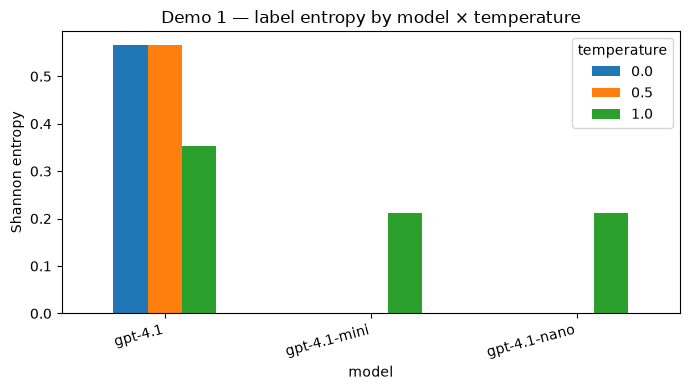

In [18]:
demo1_trials: list[dict] = []

for model in MODELS:
    for temperature in DEMO1_TEMPERATURES:
        skipped_remaining = False
        for trial in range(DEMO1_N):
            # Fresh messages list each trial (FR-005 / VC-005).
            messages = [{"role": "user", "content": DEMO1_PROMPT}]
            result = safe_chat(model, messages, temperature=temperature)
            if not result.ok:
                print(
                    f"SKIP Demo 1: model={model!r} temperature={temperature} "
                    f"trial={trial} — remaining trials for this model×temperature skipped."
                )
                skipped_remaining = True
                break
            label = extract_label(result.text or "")
            demo1_trials.append(
                {
                    "model": model,
                    "temperature": temperature,
                    "trial": trial,
                    "label": label,
                    "reply": result.text,
                }
            )
        if skipped_remaining:
            continue

demo1_trials_df = pd.DataFrame(demo1_trials)

demo1_metrics_rows: list[dict] = []
for model in MODELS:
    for temperature in DEMO1_TEMPERATURES:
        if demo1_trials_df.empty:
            labels: list[str] = []
        else:
            mask = (demo1_trials_df["model"] == model) & (
                demo1_trials_df["temperature"] == temperature
            )
            labels = demo1_trials_df.loc[mask, "label"].tolist()
        n_trials = len(labels)
        if n_trials == 0:
            print(
                f"NOTE: no successful labels for model={model!r} temperature={temperature} "
                "(model unavailable or all trials skipped)."
            )
            demo1_metrics_rows.append(
                {
                    "model": model,
                    "temperature": temperature,
                    "n_trials": 0,
                    "distinct_label_count": 0,
                    "shannon_entropy": float("nan"),
                    "majority_share": float("nan"),
                }
            )
            continue
        demo1_metrics_rows.append(
            {
                "model": model,
                "temperature": temperature,
                "n_trials": n_trials,
                "distinct_label_count": len(set(labels)),
                "shannon_entropy": shannon_entropy(labels),
                "majority_share": majority_share(labels),
            }
        )

demo1_metrics = pd.DataFrame(demo1_metrics_rows)
print("Demo 1 metrics (distinct-label count, Shannon entropy, majority-share):")
display(demo1_metrics)

for row in demo1_metrics.itertuples():
    if row.n_trials == 0:
        continue
    print(
        f"{row.model} @ temperature={row.temperature}: "
        f"n={row.n_trials}, distinct={row.distinct_label_count}, "
        f"entropy={row.shannon_entropy:.3f}, majority_share={row.majority_share:.3f}"
    )
    if row.shannon_entropy > 0:
        print(
            "  → entropy > 0: exact-match evaluation against a single label "
            "would be unreliable here."
        )

# Optional bar chart: entropy by model × temperature
plot_df = demo1_metrics.dropna(subset=["shannon_entropy"])
plot_df = plot_df[plot_df["n_trials"] > 0]
if not plot_df.empty:
    fig, ax = plt.subplots(figsize=(7, 4))
    pivot = plot_df.pivot(
        index="model", columns="temperature", values="shannon_entropy"
    )
    pivot.plot(kind="bar", ax=ax)
    ax.set_ylabel("Shannon entropy")
    ax.set_title("Demo 1 — label entropy by model × temperature")
    ax.legend(title="temperature")
    ax.set_ylim(bottom=0)
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No entropy bars to plot (no successful trials).")

# Demo 2 — top_p (nucleus sampling)

**Goal.** Compare how nucleus sampling (`top_p`) reshapes a short creative reply when the cumulative-probability mass of candidate tokens is restricted, at a fixed `temperature=0.8`.

**Method.** Use one fixed open-ended prompt that asks for at most about three sentences. For each model in `MODELS` and each `top_p` in `{0.1, 0.5, 1.0}`, make **one** independent completion at `temperature=0.8` with that `top_p` (fresh `messages` each call). Display the raw reply text in a table keyed by `(model, top_p)`. If a call fails, record an explicit skip note (FR-003 / BR-008) and continue.

**What to look for.** `top_p` limits the cumulative-probability mass of the token candidates that remain eligible for sampling. Extreme low `top_p` (e.g. `0.1`) tends toward safer / more peaked wording; `top_p=1.0` keeps the full distribution (given the fixed temperature). Middle values sit between those extremes. Compare wording diversity and "safety" of phrasing across the three `top_p` values for the same model.

**How to read the result.** Each row is one `(model, top_p)` sample at `temperature=0.8` — not a multi-trial metric. Differences illustrate nucleus sampling under a constant temperature; they are not a pass/fail quality score. Prefer lower `top_p` when you want more peaked / conservative wording at a given temperature; prefer `top_p=1.0` when you want the full temperature-driven distribution.


In [19]:
# Fixed creative / open-ended prompt (FR-020, BR-010 / VC-024).
DEMO2_TOP_P_VALUES = (0.1, 0.5, 1.0)
DEMO2_TEMPERATURE = 0.8  # FR-020 / VC-022

DEMO2_PROMPT = (
    "Invent a tiny fictional gadget that solves an everyday annoyance. "
    "Give it a playful name and describe what it does in at most three sentences."
)

print(f"DEMO2_TEMPERATURE={DEMO2_TEMPERATURE}")
print(f"DEMO2_TOP_P_VALUES={DEMO2_TOP_P_VALUES}")
print(f"DEMO2_PROMPT:\n{DEMO2_PROMPT}")


DEMO2_TEMPERATURE=0.8
DEMO2_TOP_P_VALUES=(0.1, 0.5, 1.0)
DEMO2_PROMPT:
Invent a tiny fictional gadget that solves an everyday annoyance. Give it a playful name and describe what it does in at most three sentences.


In [20]:
demo2_rows: list[dict] = []

for model in MODELS:
    for top_p in DEMO2_TOP_P_VALUES:
        # Fresh messages each call (FR-005).
        messages = [{"role": "user", "content": DEMO2_PROMPT}]
        result = safe_chat(
            model,
            messages,
            param_name="top_p",
            temperature=DEMO2_TEMPERATURE,
            top_p=top_p,
        )
        if result.ok:
            status = "ok"
            reply = result.text or ""
        else:
            status = "unsupported" if result.unsupported else "skipped"
            reply = result.error or "(no detail)"
            print(
                f"SKIP Demo 2: model={model!r} top_p={top_p} status={status} — {reply}"
            )
        demo2_rows.append(
            {
                "model": model,
                "top_p": top_p,
                "temperature": DEMO2_TEMPERATURE,
                "status": status,
                "reply": reply,
            }
        )

demo2_samples = pd.DataFrame(demo2_rows)
print("Demo 2 samples keyed by (model, top_p) at temperature=0.8:")
display(demo2_samples)

# Confirm each (model, top_p) triple appears exactly once (or as an explicit skip row).
expected = {(m, p) for m in MODELS for p in DEMO2_TOP_P_VALUES}
observed = {(row["model"], row["top_p"]) for row in demo2_rows}
assert expected == observed, f"missing/extra (model, top_p) rows: {expected ^ observed}"
print(
    f"Grid coverage: {len(demo2_rows)} rows for {len(expected)} (model, top_p) triples."
)


Demo 2 samples keyed by (model, top_p) at temperature=0.8:


,model,top_p,temperature,status,reply
0,gpt-4.1-mini,0.1,0.8,ok,Meet the Sock Snatcher: a miniature magnetic c...
1,gpt-4.1-mini,0.5,0.8,ok,"Meet the SnaggleZap: a miniature, clip-on devi..."
2,gpt-4.1-mini,1.0,0.8,ok,"Meet the **Sock Snatcher** — a compact, sock-s..."
3,gpt-4.1,0.1,0.8,ok,**Crumblerumble** \nThis pocket-sized vacuum ...
4,gpt-4.1,0.5,0.8,ok,**Crumblerumble** \nThis pocket-sized vacuum ...
5,gpt-4.1,1.0,0.8,ok,**Gadget Name:** Crumblenator\n\nTired of cook...
6,gpt-4.1-nano,0.1,0.8,ok,"Introducing the ""Sock Snugger""! This tiny, ani..."
7,gpt-4.1-nano,0.5,0.8,ok,"Introducing the ""Sock Snugger""! This tiny, che..."
8,gpt-4.1-nano,1.0,0.8,ok,"Introducing the ""SockSnugger""! This tiny, chee..."


Grid coverage: 9 rows for 9 (model, top_p) triples.


# Demo 3 — max_tokens

**Goal.** Show how `max_tokens` caps generated reply length (not prompt length), producing mid-sentence truncation at tiny budgets, and that this is a cost/latency control rather than a quality knob.

**Method.** Use one fixed multi-paragraph explanation prompt. For each model in `MODELS` and each `max_tokens` in `{16, 64, 256}`, make **one** independent completion at `temperature=0` with that `max_tokens` only (fresh `messages` each call). Display the raw reply text — including truncated replies — in a table keyed by `(model, max_tokens)`. If a call fails or the proxy rejects `max_tokens`, record an explicit skip note (FR-003 / BR-008) and continue.

**What to look for.** Small `max_tokens` (e.g. `16`) should cut the answer short, often mid-sentence. Larger budgets (`64`, then `256`) allow progressively more of the explanation. Compare character/token length across the three values for the same model; truncation is the signal, not polish.

**How to read the result.** Each row is one `(model, max_tokens)` sample at `temperature=0`. Use `max_tokens` as a hard budget for cost and latency control, not as a creativity or quality dial. Prefer a budget large enough for a complete answer in production; use tiny budgets only when you intentionally want a short stop.


In [21]:
# Fixed multi-paragraph explanation prompt (FR-030, BR-010 / VC-024).
DEMO3_MAX_TOKENS_VALUES = (16, 64, 256)
DEMO3_TEMPERATURE = 0  # FR-030 / VC-022 (explicit; matches helper default)

DEMO3_PROMPT = (
    "Explain how a public library catalog system works for a curious beginner. "
    "Write several short paragraphs covering: (1) how books are classified and shelved, "
    "(2) how a patron searches and borrows an item, (3) what happens when a book is overdue "
    "or reserved by someone else, and (4) how librarians keep the collection accurate over time. "
    "Use plain language and include concrete everyday examples in each paragraph."
)

print(f"DEMO3_TEMPERATURE={DEMO3_TEMPERATURE}")
print(f"DEMO3_MAX_TOKENS_VALUES={DEMO3_MAX_TOKENS_VALUES}")
print(f"DEMO3_PROMPT:\n{DEMO3_PROMPT}")


DEMO3_TEMPERATURE=0
DEMO3_MAX_TOKENS_VALUES=(16, 64, 256)
DEMO3_PROMPT:
Explain how a public library catalog system works for a curious beginner. Write several short paragraphs covering: (1) how books are classified and shelved, (2) how a patron searches and borrows an item, (3) what happens when a book is overdue or reserved by someone else, and (4) how librarians keep the collection accurate over time. Use plain language and include concrete everyday examples in each paragraph.


In [23]:
demo3_rows: list[dict] = []

for model in MODELS:
    for max_tokens in DEMO3_MAX_TOKENS_VALUES:
        # Fresh messages each call (FR-005).
        messages = [{"role": "user", "content": DEMO3_PROMPT}]
        result = safe_chat(
            model,
            messages,
            param_name="max_tokens",
            temperature=DEMO3_TEMPERATURE,
            max_tokens=max_tokens,
        )
        if result.ok:
            status = "ok"
            reply = result.text or ""
            print(model, max_tokens, reply)
        else:
            status = "unsupported" if result.unsupported else "skipped"
            reply = result.error or "(no detail)"
            print(
                f"SKIP Demo 3: model={model!r} max_tokens={max_tokens} "
                f"status={status} — {reply}"
            )
        demo3_rows.append(
            {
                "model": model,
                "max_tokens": max_tokens,
                "temperature": DEMO3_TEMPERATURE,
                "status": status,
                "reply_len": len(reply) if status == "ok" else None,
                "reply": reply,
            }
        )

demo3_samples = pd.DataFrame(demo3_rows)
print("Demo 3 samples keyed by (model, max_tokens) at temperature=0:")
display(demo3_samples)

# Confirm each (model, max_tokens) triple appears exactly once (or as an explicit skip row).
expected = {(m, t) for m in MODELS for t in DEMO3_MAX_TOKENS_VALUES}
observed = {(row["model"], row["max_tokens"]) for row in demo3_rows}
assert expected == observed, (
    f"missing/extra (model, max_tokens) rows: {expected ^ observed}"
)
print(
    f"Grid coverage: {len(demo3_rows)} rows for {len(expected)} (model, max_tokens) triples."
)

# Length comparison for models that succeed at both 16 and 256 (VC-010).
print("\nLength comparison (max_tokens=16 vs 256) for successful models:")
for model in MODELS:
    by_mt = {
        row["max_tokens"]: row
        for row in demo3_rows
        if row["model"] == model and row["status"] == "ok"
    }
    if 16 in by_mt and 256 in by_mt:
        len16 = by_mt[16]["reply_len"]
        len256 = by_mt[256]["reply_len"]
        print(f"  {model}: len@16={len16}, len@256={len256}")
        assert len16 < len256, (
            f"expected visibly shorter reply at max_tokens=16 than 256 for {model}: "
            f"{len16} vs {len256}"
        )
    else:
        missing = [mt for mt in (16, 256) if mt not in by_mt]
        print(f"  {model}: skip length assert (no ok reply at max_tokens={missing})")


gpt-4.1-mini 16 Sure! Imagine a public library as a big, organized treasure chest full of books
gpt-4.1-mini 64 Sure! Imagine a public library as a big, organized treasure chest full of books and other items. To keep everything easy to find, libraries use special systems to classify and shelve books. One common method is the Dewey Decimal System, which groups books by subject using numbers. For example, all books about animals might
gpt-4.1-mini 256 Sure! Imagine a public library as a big, organized treasure chest full of books and other items. To keep everything neat, libraries use special systems to classify and shelve books. One common method is the Dewey Decimal System, which groups books by subject using numbers. For example, all books about animals might be in the 590s, while books about cooking are in the 640s. This way, if you want a book about dogs, you know exactly where to look on the shelves, just like finding a specific aisle in a grocery store.

When you visit the library

,model,max_tokens,temperature,status,reply_len,reply
0,gpt-4.1-mini,16,0,ok,79,"Sure! Imagine a public library as a big, organ..."
1,gpt-4.1-mini,64,0,ok,324,"Sure! Imagine a public library as a big, organ..."
2,gpt-4.1-mini,256,0,ok,1196,"Sure! Imagine a public library as a big, organ..."
3,gpt-4.1,16,0,ok,78,**1. How books are classified and shelved:** ...
4,gpt-4.1,64,0,ok,307,**1. How books are classified and shelved:** ...
5,gpt-4.1,256,0,ok,1112,**1. How books are classified and shelved:** ...
6,gpt-4.1-nano,16,0,ok,73,Sure! Let’s start with how books are organized...
7,gpt-4.1-nano,64,0,ok,326,Sure! Let’s start with how books are organized...
8,gpt-4.1-nano,256,0,ok,1188,Sure! Let’s start with how books are organized...


Grid coverage: 9 rows for 9 (model, max_tokens) triples.

Length comparison (max_tokens=16 vs 256) for successful models:
  gpt-4.1-mini: len@16=79, len@256=1196
  gpt-4.1: len@16=78, len@256=1112
  gpt-4.1-nano: len@16=73, len@256=1188


# Demo 4 — presence_penalty

**Goal.** Show how `presence_penalty` discourages tokens that already appeared in the reply (encouraging new topics / less topic reuse), and document that OpenAI-style models typically accept it while Anthropic via this proxy may reject it with an explicit unsupported skip note.

**Method.** Use one fixed listing / topic-spread prompt. For each model in `MODELS` and each `presence_penalty` in `{0.0, 1.5}`, make **one** independent completion at `temperature=0.7` with that `presence_penalty` (fresh `messages` each call). Display the raw reply text in a table keyed by `(model, presence_penalty)`, or an explicit skip note naming the model and `presence_penalty` if the call fails or the proxy rejects the parameter (FR-003 / BR-008).

**What to look for.** At `presence_penalty=0.0`, replies may revisit the same themes or items. At `1.5`, successful models often spread across more distinct topics or list items instead of circling the same ones. If Anthropic (or another model) rejects `presence_penalty`, expect a clear unsupported/rejected skip note rather than a fabricated substitute API.

**How to read the result.** Each row is one `(model, presence_penalty)` sample at `temperature=0.7` — not a multi-trial metric. Use higher `presence_penalty` when you want broader topic coverage in a single completion; treat an unsupported skip as a provider/proxy limitation, not a demo failure. Prefer documenting the skip over inventing a workaround for classroom comparison.


In [24]:
# Fixed listing / topic-spread prompt (FR-040, BR-010 / VC-024).
DEMO4_PRESENCE_PENALTY_VALUES = (0.0, 1.5)
DEMO4_TEMPERATURE = 0.7  # FR-040 / VC-022

DEMO4_PROMPT = (
    "List eight distinct weekend activity ideas for a curious traveler visiting a coastal city. "
    "Spread across different themes (food, outdoors, culture, rest) and avoid repeating the same "
    "kind of activity. Number the items and keep each idea to one short sentence."
)

print(f"DEMO4_TEMPERATURE={DEMO4_TEMPERATURE}")
print(f"DEMO4_PRESENCE_PENALTY_VALUES={DEMO4_PRESENCE_PENALTY_VALUES}")
print(f"DEMO4_PROMPT:\n{DEMO4_PROMPT}")


DEMO4_TEMPERATURE=0.7
DEMO4_PRESENCE_PENALTY_VALUES=(0.0, 1.5)
DEMO4_PROMPT:
List eight distinct weekend activity ideas for a curious traveler visiting a coastal city. Spread across different themes (food, outdoors, culture, rest) and avoid repeating the same kind of activity. Number the items and keep each idea to one short sentence.


In [25]:
demo4_rows: list[dict] = []

for model in MODELS:
    for presence_penalty in DEMO4_PRESENCE_PENALTY_VALUES:
        # Fresh messages each call (FR-005).
        messages = [{"role": "user", "content": DEMO4_PROMPT}]
        result = safe_chat(
            model,
            messages,
            param_name="presence_penalty",
            temperature=DEMO4_TEMPERATURE,
            presence_penalty=presence_penalty,
        )
        if result.ok:
            status = "ok"
            reply = result.text or ""
            print(model, presence_penalty, reply)
        else:
            status = "unsupported" if result.unsupported else "skipped"
            reply = result.error or "(no detail)"
            print(
                f"SKIP Demo 4: model={model!r} presence_penalty={presence_penalty} "
                f"status={status} — {reply}"
            )
        demo4_rows.append(
            {
                "model": model,
                "presence_penalty": presence_penalty,
                "temperature": DEMO4_TEMPERATURE,
                "status": status,
                "reply": reply,
            }
        )

demo4_samples = pd.DataFrame(demo4_rows)
print("Demo 4 samples keyed by (model, presence_penalty) at temperature=0.7:")
display(demo4_samples)

# Confirm each (model, presence_penalty) pair appears exactly once (or as an explicit skip row).
expected = {(m, p) for m in MODELS for p in DEMO4_PRESENCE_PENALTY_VALUES}
observed = {(row["model"], row["presence_penalty"]) for row in demo4_rows}
assert expected == observed, (
    f"missing/extra (model, presence_penalty) rows: {expected ^ observed}"
)
print(
    f"Grid coverage: {len(demo4_rows)} rows for {len(expected)} (model, presence_penalty) pairs."
)

# Per-model coverage: sample or skip note naming presence_penalty (VC-011).
for model in MODELS:
    model_rows = [row for row in demo4_rows if row["model"] == model]
    assert len(model_rows) == len(DEMO4_PRESENCE_PENALTY_VALUES)
    for row in model_rows:
        if row["status"] == "ok":
            assert isinstance(row["reply"], str) and row["reply"]
        else:
            assert "presence_penalty" in str(row["reply"]).lower() or row["status"] in {
                "unsupported",
                "skipped",
            }
            print(
                f"VC-011 note for {model!r} @ presence_penalty={row['presence_penalty']}: "
                f"status={row['status']}"
            )

# VC-003: forced unsupported-style error uses unsupported wording;
# forced 401-style path does not claim unsupported.
_real_chat_demo4 = chat
try:

    def _force_unsupported_presence(*_args, **_kwargs):
        cause = _FakeHTTPError("Unsupported parameter: presence_penalty", 400)
        raise DemoLLMError(
            f"chat() failed for model='claude-haiku-4-5': {cause}"
        ) from cause

    globals()["chat"] = _force_unsupported_presence
    r_unsup = safe_chat(
        "claude-haiku-4-5",
        [{"role": "user", "content": "ping"}],
        param_name="presence_penalty",
        temperature=DEMO4_TEMPERATURE,
        presence_penalty=1.5,
    )
    assert r_unsup.ok is False and r_unsup.unsupported is True
    assert r_unsup.model == "claude-haiku-4-5"
    assert r_unsup.param_name == "presence_penalty"
    note_unsup = (
        f"SKIP unsupported/rejected parameter: model={r_unsup.model!r} "
        f"parameter={r_unsup.param_name!r} — {r_unsup.error}"
    )
    assert "unsupported" in note_unsup.lower()
    assert "presence_penalty" in note_unsup

    def _force_401_presence(*_args, **_kwargs):
        cause = _FakeHTTPError("unauthorized", 401)
        raise DemoLLMError(
            f"chat() failed for model='claude-haiku-4-5': {cause}"
        ) from cause

    globals()["chat"] = _force_401_presence
    r_auth = safe_chat(
        "claude-haiku-4-5",
        [{"role": "user", "content": "ping"}],
        param_name="presence_penalty",
        temperature=DEMO4_TEMPERATURE,
        presence_penalty=1.5,
    )
    assert r_auth.ok is False and r_auth.unsupported is False
    note_auth = (
        f"SKIP error: model={r_auth.model!r} "
        f"parameter={r_auth.param_name!r} — {r_auth.error}"
    )
    assert "unsupported/rejected parameter" not in note_auth.lower()
    print("VC-003 forced unsupported vs 401 skip wording: PASS")
finally:
    globals()["chat"] = _real_chat_demo4


gpt-4.1-mini 0.0 1. Take a morning seafood cooking class to learn local flavors.  
2. Hike a coastal trail to enjoy panoramic ocean views.  
3. Visit a maritime museum to explore the city’s nautical history.  
4. Relax with a beachfront yoga session at sunrise.  
5. Join a guided kayak tour through nearby sea caves.  
6. Attend a local music festival or open-air concert by the shore.  
7. Explore a bustling fish market and sample fresh catches.  
8. Spend an afternoon reading in a seaside botanical garden.
gpt-4.1-mini 1.5 1. Take a seafood cooking class to learn local culinary secrets.  
2. Kayak through nearby sea caves and hidden coves.  
3. Visit a coastal art gallery featuring regional artists.  
4. Relax with a beachside yoga session at sunrise.  
5. Explore a historic lighthouse and its museum.  
6. Join a guided bird-watching tour along the shore.  
7. Attend a local music festival or outdoor concert.  
8. Unwind with a sunset spa treatment overlooking the ocean.
gpt-4.1 0.0 1.

,model,presence_penalty,temperature,status,reply
0,gpt-4.1-mini,0.0,0.7,ok,1. Take a morning seafood cooking class to lea...
1,gpt-4.1-mini,1.5,0.7,ok,1. Take a seafood cooking class to learn local...
2,gpt-4.1,0.0,0.7,ok,1. Savor fresh seafood at a bustling harbor-si...
3,gpt-4.1,1.5,0.7,ok,1. Join a guided seafood tasting tour at the l...
4,gpt-4.1-nano,0.0,0.7,ok,1. Sample fresh seafood at a bustling seaside ...
5,gpt-4.1-nano,1.5,0.7,ok,1. Explore a local seafood market and sample f...


Grid coverage: 6 rows for 6 (model, presence_penalty) pairs.
SKIP unsupported/rejected parameter: model='claude-haiku-4-5' parameter='presence_penalty' — chat() failed for model='claude-haiku-4-5': Unsupported parameter: presence_penalty
SKIP error: model='claude-haiku-4-5' parameter='presence_penalty' — chat() failed for model='claude-haiku-4-5': unauthorized
VC-003 forced unsupported vs 401 skip wording: PASS


# Demo 5 — frequency_penalty

**Goal.** Show how `frequency_penalty` scales with how often a token already appeared (stronger penalty for repeats → less stuttering / phrase reuse). Contrast briefly with `presence_penalty` (Demo 4), which penalizes a token once it has appeared at all and mainly encourages topic spread. Document that OpenAI-style models typically accept `frequency_penalty` while Anthropic via this proxy may reject it — same unsupported skip pattern as Demo 4.

**Method.** Use one fixed repetition-prone prompt. For each model in `MODELS` and each `frequency_penalty` in `{0.0, 1.5}`, make **one** independent completion at `temperature=0.7` with that `frequency_penalty` (fresh `messages` each call). Display the raw reply text in a table keyed by `(model, frequency_penalty)`, or an explicit skip note naming the model and `frequency_penalty` if the call fails or the proxy rejects the parameter (FR-003 / BR-008).

**What to look for.** At `frequency_penalty=0.0`, replies may reuse the same words or sentence patterns. At `1.5`, successful models often diversify wording and reduce local repetition. Unlike `presence_penalty`, which mainly discourages revisiting tokens that already showed up once, `frequency_penalty` grows with repeat count — useful when the failure mode is stuttering the same phrase. If Anthropic (or another model) rejects `frequency_penalty`, expect a clear unsupported/rejected skip note rather than a fabricated substitute API.

**How to read the result.** Each row is one `(model, frequency_penalty)` sample at `temperature=0.7` — not a multi-trial metric. Prefer higher `frequency_penalty` when you want less word/phrase reuse in a single completion; prefer `presence_penalty` when the goal is broader topic coverage. Treat an unsupported skip as a provider/proxy limitation, not a demo failure. Prefer documenting the skip over inventing a workaround for classroom comparison.

In [26]:
# Fixed repetition-prone prompt (FR-050, BR-010 / VC-024).
DEMO5_FREQUENCY_PENALTY_VALUES = (0.0, 1.5)
DEMO5_TEMPERATURE = 0.7  # FR-050 / VC-022

DEMO5_PROMPT = (
    "Write a short promotional blurb for a plain white ceramic mug. "
    "Highlight how simple, useful, and everyday it is. "
    "If you run out of new ideas, it is fine to reuse the same selling points and phrasing."
)

print(f"DEMO5_TEMPERATURE={DEMO5_TEMPERATURE}")
print(f"DEMO5_FREQUENCY_PENALTY_VALUES={DEMO5_FREQUENCY_PENALTY_VALUES}")
print(f"DEMO5_PROMPT:\n{DEMO5_PROMPT}")


DEMO5_TEMPERATURE=0.7
DEMO5_FREQUENCY_PENALTY_VALUES=(0.0, 1.5)
DEMO5_PROMPT:
Write a short promotional blurb for a plain white ceramic mug. Highlight how simple, useful, and everyday it is. If you run out of new ideas, it is fine to reuse the same selling points and phrasing.


In [27]:
demo5_rows: list[dict] = []

for model in MODELS:
    for frequency_penalty in DEMO5_FREQUENCY_PENALTY_VALUES:
        # Fresh messages each call (FR-005).
        messages = [{"role": "user", "content": DEMO5_PROMPT}]
        result = safe_chat(
            model,
            messages,
            param_name="frequency_penalty",
            temperature=DEMO5_TEMPERATURE,
            frequency_penalty=frequency_penalty,
        )
        if result.ok:
            status = "ok"
            reply = result.text or ""
            print(model, frequency_penalty, reply)
        else:
            status = "unsupported" if result.unsupported else "skipped"
            reply = result.error or "(no detail)"
            print(
                f"SKIP Demo 5: model={model!r} frequency_penalty={frequency_penalty} "
                f"status={status} — {reply}"
            )
        demo5_rows.append(
            {
                "model": model,
                "frequency_penalty": frequency_penalty,
                "temperature": DEMO5_TEMPERATURE,
                "status": status,
                "reply": reply,
            }
        )

demo5_samples = pd.DataFrame(demo5_rows)
print("Demo 5 samples keyed by (model, frequency_penalty) at temperature=0.7:")
display(demo5_samples)

# Confirm each (model, frequency_penalty) pair appears exactly once (or as an explicit skip row).
expected = {(m, p) for m in MODELS for p in DEMO5_FREQUENCY_PENALTY_VALUES}
observed = {(row["model"], row["frequency_penalty"]) for row in demo5_rows}
assert expected == observed, (
    f"missing/extra (model, frequency_penalty) rows: {expected ^ observed}"
)
print(
    f"Grid coverage: {len(demo5_rows)} rows for {len(expected)} (model, frequency_penalty) pairs."
)

# Per-model coverage: sample or skip note naming frequency_penalty (VC-012).
for model in MODELS:
    model_rows = [row for row in demo5_rows if row["model"] == model]
    assert len(model_rows) == len(DEMO5_FREQUENCY_PENALTY_VALUES)
    for row in model_rows:
        if row["status"] == "ok":
            assert isinstance(row["reply"], str) and row["reply"]
        else:
            assert "frequency_penalty" in str(row["reply"]).lower() or row[
                "status"
            ] in {
                "unsupported",
                "skipped",
            }
            print(
                f"VC-012 note for {model!r} @ frequency_penalty={row['frequency_penalty']}: "
                f"status={row['status']}"
            )


gpt-4.1-mini 0.0 Discover the beauty of simplicity with our plain white ceramic mug. Perfectly designed for everyday use, this classic mug is your go-to companion for morning coffee, afternoon tea, or any favorite beverage. Its clean, minimalist look fits effortlessly into any kitchen or office setting, making it as useful as it is timeless. Embrace the everyday essential that never goes out of style—our plain white ceramic mug is simplicity and functionality in one perfect cup.
gpt-4.1-mini 1.5 Discover the beauty of simplicity with our plain white ceramic mug. Perfectly designed for everyday use, this classic mug is your go-to companion for morning coffee, afternoon tea, or any favorite beverage. Its clean, minimalist look fits seamlessly into any kitchen or office space. Durable and practical, it’s a timeless essential that makes every sip feel just right. Embrace the simple joy of a plain white ceramic mug—useful, reliable, and made for daily moments.
gpt-4.1 0.0 Meet your new favo

,model,frequency_penalty,temperature,status,reply
0,gpt-4.1-mini,0.0,0.7,ok,Discover the beauty of simplicity with our pla...
1,gpt-4.1-mini,1.5,0.7,ok,Discover the beauty of simplicity with our pla...
2,gpt-4.1,0.0,0.7,ok,"Meet your new favorite mug: simple, sturdy, an..."
3,gpt-4.1,1.5,0.7,ok,Discover the beauty of simplicity with our pla...
4,gpt-4.1-nano,0.0,0.7,ok,Start your day with the classic simplicity of ...
5,gpt-4.1-nano,1.5,0.7,ok,Start your day with the classic simplicity of ...


Grid coverage: 6 rows for 6 (model, frequency_penalty) pairs.


# Demo 6 — seed / reproducibility

**Goal.** Show that a fixed `seed` (when the provider/proxy accepts it) aims at reproducible sampling for the same prompt and other parameters. Support is provider/proxy-dependent, and temperature still interacts with randomness — do **not** assume bit-identical output across providers even with the same seed.

**Method.** Use one fixed short non-trivial prompt. For each model in `MODELS`: if `seed` is accepted, run **3** independent completions at `seed=42` and `temperature=0.8`, then **2** at `seed=99` and `temperature=0.8` (fresh `messages` each trial). Display all texts keyed by `(model, seed, trial)` and print an **observational** yes/no (exact string equality of the three `seed=42` replies). If `seed` is rejected, print an explicit skip note naming `seed` (FR-003 / BR-008) and do not fabricate reproducibility claims.

**What to look for.** When `seed` works, the three `seed=42` texts may match exactly (or may still differ — both outcomes are valid classroom observations). The `seed=99` pair is there for contrast under a different seed, not as a pass/fail check. If a model/proxy rejects `seed`, expect a clear unsupported/rejected skip note rather than invented identical outputs.

**How to read the result.** The identical flag for the three `seed=42` texts is **observational only** — `true` or `false` is a valid outcome, not a test failure either way. Treat support as provider/proxy-dependent; prefer documenting a skip over claiming cross-provider bit-identity. Use `seed` when you want more repeatable sampling on a backend that honors it; keep temperature in mind, since higher temperature still leaves room for divergence even with a fixed seed.

In [33]:
# Fixed short non-trivial prompt (FR-060, BR-010 / VC-024).
DEMO6_SEED_SAME = 42
DEMO6_SEED_OTHER = 99
DEMO6_N_SAME = 5
DEMO6_N_OTHER = 3
DEMO6_TEMPERATURE = 0.3  # FR-060 / VC-022

DEMO6_PROMPT = (
    "In two or three sentences, invent a quirky name and a one-sentence backstory "
    "for a fictional neighborhood bookstore that specializes in maps."
)

print(f"DEMO6_TEMPERATURE={DEMO6_TEMPERATURE}")
print(f"DEMO6_SEED_SAME={DEMO6_SEED_SAME} (×{DEMO6_N_SAME})")
print(f"DEMO6_SEED_OTHER={DEMO6_SEED_OTHER} (×{DEMO6_N_OTHER})")
print(f"DEMO6_PROMPT:\n{DEMO6_PROMPT}")


DEMO6_TEMPERATURE=0.3
DEMO6_SEED_SAME=42 (×5)
DEMO6_SEED_OTHER=99 (×3)
DEMO6_PROMPT:
In two or three sentences, invent a quirky name and a one-sentence backstory for a fictional neighborhood bookstore that specializes in maps.


In [34]:
demo6_rows: list[dict] = []

for model in MODELS:
    seed42_texts: list[str] = []
    model_failed = False

    trial_plan = [(DEMO6_SEED_SAME, i) for i in range(DEMO6_N_SAME)] + [
        (DEMO6_SEED_OTHER, i) for i in range(DEMO6_N_OTHER)
    ]

    for seed, trial_idx in trial_plan:
        # Fresh messages each trial (FR-005 / VC-005).
        messages = [{"role": "user", "content": DEMO6_PROMPT}]
        result = safe_chat(
            model,
            messages,
            param_name="seed",
            temperature=DEMO6_TEMPERATURE,
            seed=seed,
        )
        if not result.ok:
            status = "unsupported" if result.unsupported else "skipped"
            reply = result.error or "(no detail)"
            print(
                f"SKIP Demo 6: model={model!r} parameter='seed' "
                f"status={status} — {reply}"
            )
            demo6_rows.append(
                {
                    "model": model,
                    "seed": seed,
                    "trial": trial_idx,
                    "temperature": DEMO6_TEMPERATURE,
                    "status": status,
                    "reply": reply,
                    "seed42_identical": None,
                }
            )
            model_failed = True
            break

        text = result.text or ""
        if seed == DEMO6_SEED_SAME:
            seed42_texts.append(text)
        demo6_rows.append(
            {
                "model": model,
                "seed": seed,
                "trial": trial_idx,
                "temperature": DEMO6_TEMPERATURE,
                "status": "ok",
                "reply": text,
                "seed42_identical": None,
            }
        )

    if model_failed:
        continue

    # Observational only — not a pass/fail gate (FR-060 / VC-013).
    identical = len(seed42_texts) == DEMO6_N_SAME and len(set(seed42_texts)) == 1
    print(
        f"Observational (not a test gate): model={model!r} "
        f"seed={DEMO6_SEED_SAME} ×{DEMO6_N_SAME} identical={identical}"
    )
    for row in demo6_rows:
        if row["model"] == model and row["status"] == "ok":
            row["seed42_identical"] = identical

demo6_samples = pd.DataFrame(demo6_rows)
print(
    f"Demo 6 samples keyed by (model, seed, trial) at temperature={DEMO6_TEMPERATURE}:"
)
display(demo6_samples)

# VC-013: each model has 3+2 texts + observational flag, or a skip note naming seed.
for model in MODELS:
    model_rows = [row for row in demo6_rows if row["model"] == model]
    assert model_rows, f"model {model!r} missing Demo 6 rows"
    ok_rows = [row for row in model_rows if row["status"] == "ok"]
    if ok_rows:
        seed42 = [row for row in ok_rows if row["seed"] == DEMO6_SEED_SAME]
        seed99 = [row for row in ok_rows if row["seed"] == DEMO6_SEED_OTHER]
        assert len(seed42) == DEMO6_N_SAME, (
            f"{model!r}: expected {DEMO6_N_SAME} seed=42 texts"
        )
        assert len(seed99) == DEMO6_N_OTHER, (
            f"{model!r}: expected {DEMO6_N_OTHER} seed=99 texts"
        )
        assert ok_rows[0]["seed42_identical"] is not None
        print(
            f"VC-013: model={model!r} has 3+2 texts; "
            f"identical={ok_rows[0]['seed42_identical']}"
        )
    else:
        skip_row = model_rows[0]
        assert skip_row["status"] in {"unsupported", "skipped"}
        assert (
            "seed" in str(skip_row["reply"]).lower() or skip_row.get("seed") is not None
        )
        print(
            f"VC-013: model={model!r} skip note naming seed; "
            f"status={skip_row['status']}"
        )

print(
    "VC-013 note: identical flag is observational only (true/false both valid); "
    "Markdown does not claim cross-provider bit-identical reproducibility."
)


Observational (not a test gate): model='gpt-4.1-mini' seed=42 ×5 identical=False
Observational (not a test gate): model='gpt-4.1' seed=42 ×5 identical=False
Observational (not a test gate): model='gpt-4.1-nano' seed=42 ×5 identical=False
Demo 6 samples keyed by (model, seed, trial) at temperature=0.3:


,model,seed,trial,temperature,status,reply,seed42_identical
0,gpt-4.1-mini,42,0,0.3,ok,**The Wandering Quill** — Nestled between cobb...,False
1,gpt-4.1-mini,42,1,0.3,ok,**The Wandering Quill** — Nestled between cobb...,False
2,gpt-4.1-mini,42,2,0.3,ok,**The Wandering Quill** — Nestled between cobb...,False
3,gpt-4.1-mini,42,3,0.3,ok,**The Wandering Quill** — Nestled between cobb...,False
4,gpt-4.1-mini,42,4,0.3,ok,**The Wandering Quill** — Nestled between cobb...,False
5,gpt-4.1-mini,99,0,0.3,ok,**The Wandering Quill** — Nestled between cobb...,False
6,gpt-4.1-mini,99,1,0.3,ok,**The Wandering Quill** — Nestled between cobb...,False
7,gpt-4.1-mini,99,2,0.3,ok,**The Wandering Quill** is a cozy nook where e...,False
8,gpt-4.1,42,0,0.3,ok,**Name:** The Wandering Page\n\n**Backstory:**...,False
9,gpt-4.1,42,1,0.3,ok,**Name:** The Wandering Page\n\n**Backstory:**...,False


VC-013: model='gpt-4.1-mini' has 3+2 texts; identical=False
VC-013: model='gpt-4.1' has 3+2 texts; identical=False
VC-013: model='gpt-4.1-nano' has 3+2 texts; identical=False
VC-013 note: identical flag is observational only (true/false both valid); Markdown does not claim cross-provider bit-identical reproducibility.
